### 算loocv svd 和畫空間分布

In [14]:
import numpy as np
import pandas as pd
import xarray as xr
from xmca.xarray import xMCA
from scipy import stats
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
import os

# ==============================================================================
# 1. 檔案路徑與參數設定
# ==============================================================================
from pathlib import Path
REPO_ROOT = Path.cwd()
DATA_ROOT = Path(os.environ.get('PBF_DATA_ROOT', REPO_ROOT))
url1 = str(DATA_ROOT / 'data' / 'raw' / 'sst.mnmean1.nc')  # 觀測 SST 檔案

output_dir = str(REPO_ROOT / 'data' / 'processed')
plot_out_dir = str(REPO_ROOT / 'data' / 'processed' / 'fig2_plots')

output_csv_loocv_path = os.path.join(output_dir, 'obs_SVD_LOOCV_raw_1981_2020.csv')
output_csv_40folds_pcs_path = os.path.join(output_dir, 'all_40folds_39years_PO_AO_PCs_1981_2020_regenerated.csv')
original_training_csv_path = str(DATA_ROOT / 'data' / 'raw' / 'all_40folds_39years_PO_AO_PCs_1981_2020.csv')
comparison_csv_path = os.path.join(output_dir, 'all_40folds_39years_PO_AO_PCs_1981_2020_comparison.csv')
output_nc_path = os.path.join(output_dir, 'PanBasin_PO_AO_LOOCV_patterns_1981_2020_local.nc')

START_YEAR = '1981'
END_YEAR = '2020'
N_MODES = 3  # PO 與 AO 各前 3 個模態 (共 6 個特徵)

os.makedirs(output_dir, exist_ok=True)
os.makedirs(plot_out_dir, exist_ok=True)

# ==============================================================================
# 2. 資料讀取、篩選 10-12 月 OND 季節平均與洋盆切分
# ==============================================================================
ds_ssto = xr.open_dataset(url1)
ds_ssto_filtered = ds_ssto.sel(time=slice(START_YEAR, END_YEAR))
ds_ssto_filtered['time'] = pd.to_datetime(ds_ssto_filtered['time'].values)

month_mask = ds_ssto_filtered['time.month'].isin([10, 11, 12])
ds_ssto_ond = (
    ds_ssto_filtered.where(month_mask, drop=True)
    .groupby('time.year')
    .mean('time')
)

posst_all = ds_ssto_ond.sst.sel(lat=slice(50, 20), lon=slice(120, 210)).rename({'year': 'time'})
aosst_all = ds_ssto_ond.sst.sel(lat=slice(60, 30), lon=slice(300, 355)).rename({'year': 'time'})

# 用於最終分析繪圖的全洋盆 (Pan-Basin) 區域
panbasin_sst_all = ds_ssto_ond.sst.sel(lat=slice(75, 15), lon=slice(100, 355)).rename({'year': 'time'})

all_years = posst_all['time'].values
n_years = len(all_years)
print(f'✅ 資料預處理完成！共 {n_years} 個年份 ({all_years[0]} - {all_years[-1]})')

# ==============================================================================
# 3. 建立第 1 折基準 (Reference Fold 1: 抽掉 1981，使用 1982-2020 年)
# ==============================================================================
ref_test_year = all_years[0]
ref_train_years = all_years[all_years != ref_test_year]

posst_ref_raw = posst_all.sel(time=ref_train_years)
aosst_ref_raw = aosst_all.sel(time=ref_train_years)

clim_mean_po_ref = posst_ref_raw.mean(dim='time')
clim_mean_ao_ref = aosst_ref_raw.mean(dim='time')

posst_ref_ano = posst_ref_raw - clim_mean_po_ref
aosst_ref_ano = aosst_ref_raw - clim_mean_ao_ref

mca_ref = xMCA(posst_ref_ano, aosst_ref_ano)
mca_ref.normalize()
mca_ref.apply_coslat()
mca_ref.solve()

ref_eofs_all = mca_ref.eofs(n=N_MODES)
ref_eofs_po = [ref_eofs_all['left'].isel(mode=m) for m in range(N_MODES)]
ref_eofs_ao = [ref_eofs_all['right'].isel(mode=m) for m in range(N_MODES)]

ref_pcs_po_raw = []
ref_pcs_ao_raw = []
for m in range(N_MODES):
    pc_po_1 = (posst_ref_ano.fillna(0) * ref_eofs_po[m].fillna(0)).sum(dim=['lat', 'lon']).values
    pc_ao_1 = (aosst_ref_ano.fillna(0) * ref_eofs_ao[m].fillna(0)).sum(dim=['lat', 'lon']).values
    ref_pcs_po_raw.append(pc_po_1)
    ref_pcs_ao_raw.append(pc_ao_1)

print('=' * 95)
print('🎯【基準建立】已完成第 1 折 SVD (1982-2020 原始特徵作為對齊模板)')
print('=' * 95)

# ==============================================================================
# 4. 執行 40 折 LOOCV：計算相關係數 (Correlation) 與迴歸斜率 (Regression)
# ==============================================================================
loocv_anomaly_features = {
    'Year': [], 'obs_PO_mode1': [], 'obs_AO_mode1': [],
    'obs_PO_mode2': [], 'obs_AO_mode2': [], 'obs_PO_mode3': [], 'obs_AO_mode3': [],
}
all_40folds_records = []

# 建立字典結構分別儲存 40 折的 Correlation 與 Regression 矩陣列表
corr_patterns = {'PO': {0: [], 1: [], 2: []}, 'AO': {0: [], 1: [], 2: []}}
reg_patterns  = {'PO': {0: [], 1: [], 2: []}, 'AO': {0: [], 1: [], 2: []}}

print(
    f"{'Fold':<6} | {'TestYear':<8} | {'PO1_r':<7} {'AO1_r':<7} |"
    f" {'PO2_r':<7} {'AO2_r':<7} | {'PO3_r':<7} {'AO3_r':<7} | {'對齊翻轉狀況'}"
)
print('-' * 95)

for i, test_year in enumerate(all_years):
    train_years = all_years[all_years != test_year]

    posst_train_raw = posst_all.sel(time=train_years)
    aosst_train_raw = aosst_all.sel(time=train_years)
    posst_test_raw = posst_all.sel(time=test_year)
    aosst_test_raw = aosst_all.sel(time=test_year)
    
    panbasin_sst_train_raw = panbasin_sst_all.sel(time=train_years)

    clim_mean_po = posst_train_raw.mean(dim='time')
    clim_mean_ao = aosst_train_raw.mean(dim='time')
    clim_mean_panbasin = panbasin_sst_train_raw.mean(dim='time')

    posst_train_ano = posst_train_raw - clim_mean_po
    aosst_train_ano = aosst_train_raw - clim_mean_ao
    posst_test_ano = posst_test_raw - clim_mean_po
    aosst_test_ano = aosst_test_raw - clim_mean_ao
    
    panbasin_sst_train_ano = panbasin_sst_train_raw - clim_mean_panbasin

    mca_fold = xMCA(posst_train_ano, aosst_train_ano)
    mca_fold.normalize()
    mca_fold.apply_coslat()
    mca_fold.solve()

    eofs_all = mca_fold.eofs(n=N_MODES)
    eofs_po = [eofs_all['left'].isel(mode=m) for m in range(N_MODES)]
    eofs_ao = [eofs_all['right'].isel(mode=m) for m in range(N_MODES)]

    curr_pcs_po = []
    curr_pcs_ao = []
    for m in range(N_MODES):
        pc_po_val = (posst_train_ano.fillna(0) * eofs_po[m].fillna(0)).sum(dim=['lat', 'lon']).values
        pc_ao_val = (aosst_train_ano.fillna(0) * eofs_ao[m].fillna(0)).sum(dim=['lat', 'lon']).values
        curr_pcs_po.append(pc_po_val)
        curr_pcs_ao.append(pc_ao_val)

    flips_log = []
    r_logs = []
    overlap_years = np.intersect1d(ref_train_years, train_years)
    ref_idx = np.where(np.isin(ref_train_years, overlap_years))[0]
    curr_idx = np.where(np.isin(train_years, overlap_years))[0]

    for m in range(N_MODES):
        ref_po_sub = ref_pcs_po_raw[m][ref_idx]
        curr_po_sub = curr_pcs_po[m][curr_idx]
        r_po = float(np.corrcoef(curr_po_sub, ref_po_sub)[0, 1])

        ref_ao_sub = ref_pcs_ao_raw[m][ref_idx]
        curr_ao_sub = curr_pcs_ao[m][curr_idx]
        r_ao = float(np.corrcoef(curr_ao_sub, ref_ao_sub)[0, 1])
        
        r_logs.extend([r_po, r_ao])

        # 符號與模板對齊
        if r_po < 0:
            curr_pcs_po[m] = -1.0 * curr_pcs_po[m]
            eofs_po[m] = -1.0 * eofs_po[m]
            flips_log.append(f'PO{m+1}')

        if r_ao < 0:
            curr_pcs_ao[m] = -1.0 * curr_pcs_ao[m]
            eofs_ao[m] = -1.0 * eofs_ao[m]
            flips_log.append(f'AO{m+1}')

        # Mode 1 固定乘以 -1 (維持原設定)
        if m == 0:
            curr_pcs_po[m] = -1.0 * curr_pcs_po[m]
            eofs_po[m] = -1.0 * eofs_po[m]
            curr_pcs_ao[m] = -1.0 * curr_pcs_ao[m]
            eofs_ao[m] = -1.0 * eofs_ao[m]

        # Mode 3 固定乘以 -1 (反相)
        if m == 2:
            curr_pcs_po[m] = -1.0 * curr_pcs_po[m]
            eofs_po[m] = -1.0 * eofs_po[m]
            curr_pcs_ao[m] = -1.0 * curr_pcs_ao[m]
            eofs_ao[m] = -1.0 * eofs_ao[m]

    status_str = ', '.join(flips_log) if flips_log else '無對齊反相'
    if i == 0:
        status_str += ' (基準自身)'
        
    print(
        f'Fold {i+1:02d} | {test_year:<8} | {r_logs[0]:>6.2f} {r_logs[1]:>6.2f} |'
        f' {r_logs[2]:>6.2f} {r_logs[3]:>6.2f} | {r_logs[4]:>6.2f}'
        f' {r_logs[5]:>6.2f} | {status_str}'
    )

    for t_idx, tr_yr in enumerate(train_years):
        all_40folds_records.append({
            'Fold': i + 1, 'Left_Out_Year': int(test_year), 'Train_Year': int(tr_yr),
            'PO_PC1': curr_pcs_po[0][t_idx], 'AO_PC1': curr_pcs_ao[0][t_idx],
            'PO_PC2': curr_pcs_po[1][t_idx], 'AO_PC2': curr_pcs_ao[1][t_idx],
            'PO_PC3': curr_pcs_po[2][t_idx], 'AO_PC3': curr_pcs_ao[2][t_idx],
        })

    loocv_anomaly_features['Year'].append(int(test_year))
    for m in range(N_MODES):
        val_po = float(posst_test_ano.fillna(0).dot(eofs_po[m].fillna(0)).values)
        val_ao = float(aosst_test_ano.fillna(0).dot(eofs_ao[m].fillna(0)).values)
        loocv_anomaly_features[f'obs_PO_mode{m+1}'].append(val_po)
        loocv_anomaly_features[f'obs_AO_mode{m+1}'].append(val_ao)

    # --------------------------------------------------------------------------
    # i. 計算各網格的 Correlation 與 Regression
    # --------------------------------------------------------------------------
    y_panbasin = panbasin_sst_train_ano - panbasin_sst_train_ano.mean(dim='time')
    y_panbasin_ss = np.sqrt((y_panbasin**2).sum(dim='time'))  # 用於 Correlation
    n_samples = len(train_years)                             # 用於 Regression

    for m in range(N_MODES):
        # --- PO ---
        # 1. 相關係數 (Correlation)
        x_po_ano = curr_pcs_po[m] - np.mean(curr_pcs_po[m])
        x_po_ss = np.sqrt(np.sum(x_po_ano**2))
        x_po_ano_da = xr.DataArray(x_po_ano, dims=['time'], coords={'time': panbasin_sst_train_ano.time})
        corr_po = (y_panbasin * x_po_ano_da).sum(dim='time') / (x_po_ss * y_panbasin_ss)
        corr_patterns['PO'][m].append(corr_po)

        # 2. 迴歸斜率 (Regression, ℃/std)
        x_po_std = x_po_ano / np.std(curr_pcs_po[m], ddof=1)
        x_po_std_da = xr.DataArray(x_po_std, dims=['time'], coords={'time': panbasin_sst_train_ano.time})
        reg_po = (y_panbasin * x_po_std_da).sum(dim='time') / (n_samples - 1)
        reg_patterns['PO'][m].append(reg_po)

        # --- AO ---
        # 1. 相關係數 (Correlation)
        x_ao_ano = curr_pcs_ao[m] - np.mean(curr_pcs_ao[m])
        x_ao_ss = np.sqrt(np.sum(x_ao_ano**2))
        x_ao_ano_da = xr.DataArray(x_ao_ano, dims=['time'], coords={'time': panbasin_sst_train_ano.time})
        corr_ao = (y_panbasin * x_ao_ano_da).sum(dim='time') / (x_ao_ss * y_panbasin_ss)
        corr_patterns['AO'][m].append(corr_ao)

        # 2. 迴歸斜率 (Regression, ℃/std)
        x_ao_std = x_ao_ano / np.std(curr_pcs_ao[m], ddof=1)
        x_ao_std_da = xr.DataArray(x_ao_std, dims=['time'], coords={'time': panbasin_sst_train_ano.time})
        reg_ao = (y_panbasin * x_ao_std_da).sum(dim='time') / (n_samples - 1)
        reg_patterns['AO'][m].append(reg_ao)

# ==============================================================================
# 5. 匯出特徵資料 CSV
# ==============================================================================
df_40folds_all_pcs = pd.DataFrame(all_40folds_records)
df_40folds_all_pcs.to_csv(output_csv_40folds_pcs_path, index=False)
# Compare regenerated training predictors with the preserved original; never overwrite it.
df_original = pd.read_csv(original_training_csv_path)
key_cols = ['Fold', 'Left_Out_Year', 'Train_Year']
predictor_cols = ['PO_PC1', 'AO_PC1', 'PO_PC2', 'AO_PC2', 'PO_PC3', 'AO_PC3']
df_reg = df_40folds_all_pcs.sort_values(key_cols).reset_index(drop=True)
df_orig = df_original.sort_values(key_cols).reset_index(drop=True)
if not df_reg[key_cols].equals(df_orig[key_cols]):
    raise ValueError('Fold/year keys differ between regenerated and original training tables')
comparison = pd.DataFrame({
    'Predictor': predictor_cols,
    'Max_Abs_Difference': [float(np.max(np.abs(df_reg[c].to_numpy(float) - df_orig[c].to_numpy(float)))) for c in predictor_cols],
})
# Resolve only verified global sign reversals against the authoritative model CSV.
sign_corrections = {}
for col in predictor_cols:
    x = df_reg[col].to_numpy(float); y = df_orig[col].to_numpy(float)
    same = float(np.max(np.abs(x - y)))
    opposite = float(np.max(np.abs(-x - y)))
    if same <= 1e-6:
        sign_corrections[col] = 1.0
    elif opposite <= 1e-6:
        sign_corrections[col] = -1.0
    else:
        raise ValueError(f'Unresolved training mismatch for {col}: same={same}, opposite={opposite}')
comparison['Verified_Sign_Correction'] = [sign_corrections[c] for c in predictor_cols]
comparison['Max_Abs_Difference_After_Correction'] = [float(np.max(np.abs(sign_corrections[c] * df_reg[c].to_numpy(float) - df_orig[c].to_numpy(float)))) for c in predictor_cols]
comparison.to_csv(comparison_csv_path, index=False)

df_obs_ano = pd.DataFrame(loocv_anomaly_features)
# Save raw held-out projections in the same predictor scale as the training table.
df_obs_raw = df_obs_ano.rename(columns={
    'Year': 'Year', 'obs_PO_mode1': 'PO_PC1', 'obs_AO_mode1': 'AO_PC1',
    'obs_PO_mode2': 'PO_PC2', 'obs_AO_mode2': 'AO_PC2',
    'obs_PO_mode3': 'PO_PC3', 'obs_AO_mode3': 'AO_PC3',
})[['Year', *predictor_cols]]
for col in predictor_cols:
    df_obs_raw[col] = df_obs_raw[col] * sign_corrections[col]
df_obs_raw.to_csv(output_csv_loocv_path, index=False)

print('\n' + '=' * 95)
print('✅ 【CSV 特徵檔案匯出完成】')
print('=' * 95)

# ==============================================================================
# 6. 顯著性檢定、繪圖並儲存至 NetCDF 4D 陣列
# ==============================================================================
print('🎯【顯著性檢定、繪圖與 NC 儲存】開始處理 6 個 Mode...')

basins = ['PO', 'AO']
modes = [1, 2, 3]

ref_lat = panbasin_sst_all['lat'].values
ref_lon = panbasin_sst_all['lon'].values

shape_4d = (len(basins), len(modes), len(ref_lat), len(ref_lon))

# 初始化存放於 NetCDF 的矩陣
arr_mean_corr = np.full(shape_4d, np.nan, dtype=np.float32)
arr_std_corr  = np.full(shape_4d, np.nan, dtype=np.float32)
arr_t_corr    = np.full(shape_4d, np.nan, dtype=np.float32)
arr_p_corr    = np.full(shape_4d, np.nan, dtype=np.float32)
arr_sig_corr  = np.full(shape_4d, np.nan, dtype=np.float32)

arr_mean_reg  = np.full(shape_4d, np.nan, dtype=np.float32)
arr_std_reg   = np.full(shape_4d, np.nan, dtype=np.float32)
arr_t_reg     = np.full(shape_4d, np.nan, dtype=np.float32)
arr_p_reg     = np.full(shape_4d, np.nan, dtype=np.float32)
arr_sig_reg   = np.full(shape_4d, np.nan, dtype=np.float32)

def plot_and_save(data_2d, mask_2d, clevs, cbar_label, cbar_ticks, title_str, save_filename):
    """通用 Cartopy 繪圖函式"""
    fig = plt.figure(figsize=(11, 8.5))
    ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=225))
    
    lons = ref_lon
    lats = ref_lat
    data_mean_cyc, lon_cyc = add_cyclic_point(data_2d, coord=lons)
    mask_cyc, _            = add_cyclic_point(mask_2d, coord=lons)
    
    cs = ax.contourf(
        lon_cyc, lats, data_mean_cyc, clevs,
        transform=ccrs.PlateCarree(), cmap='coolwarm', extend='both'
    )
    ax.contourf(
        lon_cyc, lats, mask_cyc, [0, 1],
        transform=ccrs.PlateCarree(), colors='none', hatches=['.', '.'],
        extend='both', alpha=0
    )
    ax.coastlines(resolution='50m', color='black', linewidth=1)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', zorder=2)
    ax.gridlines(draw_labels=False, linestyle='--', alpha=0.5)
    
    ax.set_extent([100, 355, 15, 75], crs=ccrs.PlateCarree())
    ax.set_xticks(np.arange(100, 355, 45), crs=ccrs.PlateCarree())
    ax.set_yticks(np.arange(15, 76, 15), crs=ccrs.PlateCarree())
    ax.xaxis.set_major_formatter(cticker.LongitudeFormatter())
    ax.yaxis.set_major_formatter(cticker.LatitudeFormatter())
    ax.tick_params(axis='both', labelsize=18)
    
    cbar = plt.colorbar(cs, orientation='horizontal', shrink=0.7, pad=0.12, ticks=cbar_ticks)
    cbar.ax.tick_params(labelsize=16)
    cbar.set_label(cbar_label, fontsize=18)
    plt.title(title_str, fontsize=20, loc='left', pad=15)
    
    save_path = os.path.join(plot_out_dir, save_filename)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.close(fig)

for b_idx, basin in enumerate(basins):
    for m_idx, m in enumerate(range(N_MODES)):
        mode_col = f'{basin} Mode{m+1}'
        print(f'正在統計檢定與繪圖: {mode_col} ...')

        # ----------------------------------------------------------------------
        # A. 相關係數 (Correlation) 統計與檢定
        # ----------------------------------------------------------------------
        da_corr_folds = xr.concat(corr_patterns[basin][m], dim='fold')
        mean_corr = da_corr_folds.mean(dim='fold').values
        std_corr  = da_corr_folds.std(dim='fold', ddof=1).values
        n_folds = len(da_corr_folds['fold'])
        
        t_stat_corr = mean_corr / (std_corr / np.sqrt(n_folds))
        p_val_corr  = 2.0 * (1.0 - stats.t.cdf(np.abs(t_stat_corr), df=n_folds - 1))
        mask_corr_plot = np.where(p_val_corr < 0.05, 1.0, np.nan)
        
        arr_mean_corr[b_idx, m_idx, :, :] = mean_corr
        arr_std_corr[b_idx, m_idx, :, :]  = std_corr
        arr_t_corr[b_idx, m_idx, :, :]    = t_stat_corr
        arr_p_corr[b_idx, m_idx, :, :]    = p_val_corr
        arr_sig_corr[b_idx, m_idx, :, :]  = np.where(p_val_corr < 0.05, 1.0, 0.0)

        # 繪製 Correlation 圖
        plot_and_save(
            data_2d=mean_corr, mask_2d=mask_corr_plot,
            clevs=np.arange(-0.8, 0.81, 0.1),
            cbar_label='Correlation Coefficient',
            cbar_ticks=np.arange(-0.8, 0.81, 0.2),
            title_str=f'{mode_col} Correlation',
            save_filename=f'{mode_col}_PanBasin_Correlation_LOOCV_sig.svg'
        )

        # ----------------------------------------------------------------------
        # B. 迴歸斜率 (Regression, ℃/std) 統計與檢定
        # ----------------------------------------------------------------------
        da_reg_folds = xr.concat(reg_patterns[basin][m], dim='fold')
        mean_reg = da_reg_folds.mean(dim='fold').values
        std_reg  = da_reg_folds.std(dim='fold', ddof=1).values
        
        t_stat_reg = mean_reg / (std_reg / np.sqrt(n_folds))
        p_val_reg  = 2.0 * (1.0 - stats.t.cdf(np.abs(t_stat_reg), df=n_folds - 1))
        mask_reg_plot = np.where(p_val_reg < 0.05, 1.0, np.nan)
        
        arr_mean_reg[b_idx, m_idx, :, :] = mean_reg
        arr_std_reg[b_idx, m_idx, :, :]  = std_reg
        arr_t_reg[b_idx, m_idx, :, :]    = t_stat_reg
        arr_p_reg[b_idx, m_idx, :, :]    = p_val_reg
        arr_sig_reg[b_idx, m_idx, :, :]  = np.where(p_val_reg < 0.05, 1.0, 0.0)

        # 繪製 Regression 圖
        plot_and_save(
            data_2d=mean_reg, mask_2d=mask_reg_plot,
            clevs=np.arange(-1.0, 1.01, 0.1),
            cbar_label='℃/std',
            cbar_ticks=np.arange(-1.0, 1.01, 0.2),
            title_str=f'{mode_col} Regression',
            save_filename=f'{mode_col}_PanBasin_Regression_LOOCV_sig.svg'
        )

# ==============================================================================
# 7. 組裝並儲存整合型 NetCDF 檔案 (Correlation + Regression)
# ==============================================================================
coords = {
    'basin': basins,
    'mode': modes,
    'lat': ref_lat,
    'lon': ref_lon
}

ds_out = xr.Dataset(
    data_vars={
        # --- 相關分析變數 ---
        'mean_corr': (['basin', 'mode', 'lat', 'lon'], arr_mean_corr, {
            'long_name': 'Mean correlation coefficient across 40 LOOCV folds',
            'units': '1'
        }),
        'std_corr': (['basin', 'mode', 'lat', 'lon'], arr_std_corr, {
            'long_name': 'Standard deviation of correlation coefficients across 40 LOOCV folds',
            'units': '1'
        }),
        'p_val_corr': (['basin', 'mode', 'lat', 'lon'], arr_p_corr, {
            'long_name': 'Two-tailed p-value from one-sample t-test for correlation',
            'units': '1'
        }),
        'sig_mask_corr': (['basin', 'mode', 'lat', 'lon'], arr_sig_corr, {
            'long_name': 'Correlation significance mask where p < 0.05',
            'flag_values': [0, 1],
            'flag_meanings': 'not_significant significant'
        }),
        
        # --- 迴歸分析變數 ---
        'mean_reg': (['basin', 'mode', 'lat', 'lon'], arr_mean_reg, {
            'long_name': 'Mean regression slope of SST anomaly onto standardized PC across 40 folds',
            'units': 'degC/std'
        }),
        'std_reg': (['basin', 'mode', 'lat', 'lon'], arr_std_reg, {
            'long_name': 'Standard deviation of regression slopes across 40 folds',
            'units': 'degC/std'
        }),
        'p_val_reg': (['basin', 'mode', 'lat', 'lon'], arr_p_reg, {
            'long_name': 'Two-tailed p-value from one-sample t-test for regression',
            'units': '1'
        }),
        'sig_mask_reg': (['basin', 'mode', 'lat', 'lon'], arr_sig_reg, {
            'long_name': 'Regression significance mask where p < 0.05',
            'flag_values': [0, 1],
            'flag_meanings': 'not_significant significant'
        }),
    },
    coords=coords,
    attrs={
        'title': 'Pan-Basin SST Teleconnection Patterns (LOOCV)',
        'description': 'Mean teleconnection correlation and regression patterns with significance for PO/AO Modes 1-3 (Mode 3 multiplied by -1)',
        'period': f'{START_YEAR}-{END_YEAR}',
        'n_folds': 40
    }
)

encoding = {var: {'zlib': True, 'complevel': 5} for var in ds_out.data_vars}
ds_out.to_netcdf(output_nc_path, encoding=encoding)

print('=' * 95)
print(f'✅ 整合型 NetCDF 檔案儲存成功: {output_nc_path}')
print('✅ 所有 6 個 Mode 的 Correlation 與 Regression 繪圖與檢定皆已順利完成！')
print('=' * 95)

✅ 資料預處理完成！共 40 個年份 (1981 - 2020)
🎯【基準建立】已完成第 1 折 SVD (1982-2020 原始特徵作為對齊模板)
Fold   | TestYear | PO1_r   AO1_r   | PO2_r   AO2_r   | PO3_r   AO3_r   | 對齊翻轉狀況
-----------------------------------------------------------------------------------------------
Fold 01 | 1981     |   1.00   1.00 |   1.00   1.00 |   1.00   1.00 | 無對齊反相 (基準自身)
Fold 02 | 1982     |   1.00   1.00 |   0.89   0.90 |   0.90   0.83 | 無對齊反相
Fold 03 | 1983     |   1.00   1.00 |   0.89   0.92 |   0.89   0.86 | 無對齊反相
Fold 04 | 1984     |   1.00   1.00 |   0.32   0.28 |  -0.31  -0.09 | PO3, AO3
Fold 05 | 1985     |   1.00   1.00 |   0.76   0.80 |  -0.74  -0.64 | PO3, AO3
Fold 06 | 1986     |   1.00   1.00 |   0.10   0.03 |  -0.52  -0.33 | PO3, AO3
Fold 07 | 1987     |   1.00   1.00 |  -0.76  -0.81 |   0.68   0.67 | PO2, AO2
Fold 08 | 1988     |   1.00   1.00 |   0.75   0.76 |  -0.59  -0.56 | PO3, AO3
Fold 09 | 1989     |   1.00   1.00 |   0.69   0.70 |   0.50   0.49 | 無對齊反相
Fold 10 | 1990     |   1.00   1.00 |   0.74   0.76

/tmp/ipykernel_2816383/2494629243.py:373: RuntimeWarning: invalid value encountered in divide
  t_stat_reg = mean_reg / (std_reg / np.sqrt(n_folds))


正在統計檢定與繪圖: PO Mode2 ...


/tmp/ipykernel_2816383/2494629243.py:373: RuntimeWarning: invalid value encountered in divide
  t_stat_reg = mean_reg / (std_reg / np.sqrt(n_folds))


正在統計檢定與繪圖: PO Mode3 ...


...

正在統計檢定與繪圖: AO Mode2 ...


/tmp/ipykernel_2816383/2494629243.py:373: RuntimeWarning: invalid value encountered in divide
  t_stat_reg = mean_reg / (std_reg / np.sqrt(n_folds))


正在統計檢定與繪圖: AO Mode3 ...


/tmp/ipykernel_2816383/2494629243.py:373: RuntimeWarning: invalid value encountered in divide
  t_stat_reg = mean_reg / (std_reg / np.sqrt(n_folds))


✅ 整合型 NetCDF 檔案儲存成功: <configured external output>
✅ 所有 6 個 Mode 的 Correlation 與 Regression 繪圖與檢定皆已順利完成！


In [9]:
url1 = str(DATA_ROOT / 'data' / 'raw' / 'PanBasin_PO_AO_LOOCV_patterns_1981_2020.nc')
ds_sst = xr.open_dataset(url1)
ds_sst

<xarray.Dataset>
Dimensions:        (basin: 2, mode: 3, lat: 30, lon: 128)
Coordinates:
  * basin          (basin) object 'PO' 'AO'
  * mode           (mode) int64 1 2 3
  * lat            (lat) float32 74.0 72.0 70.0 68.0 ... 22.0 20.0 18.0 16.0
  * lon            (lon) float32 100.0 102.0 104.0 106.0 ... 350.0 352.0 354.0
Data variables:
    mean_corr      (basin, mode, lat, lon) float32 ...
    std_corr       (basin, mode, lat, lon) float32 ...
    p_val_corr     (basin, mode, lat, lon) float32 ...
    sig_mask_corr  (basin, mode, lat, lon) float32 ...
    mean_reg       (basin, mode, lat, lon) float32 ...
    std_reg        (basin, mode, lat, lon) float32 ...
    p_val_reg      (basin, mode, lat, lon) float32 ...
    sig_mask_reg   (basin, mode, lat, lon) float32 ...
Attributes:
    title:        Pan-Basin SST Teleconnection Patterns (LOOCV)
    description:  Mean teleconnection correlation and regression patterns wit...
    period:       1981-2020
    n_folds:      40

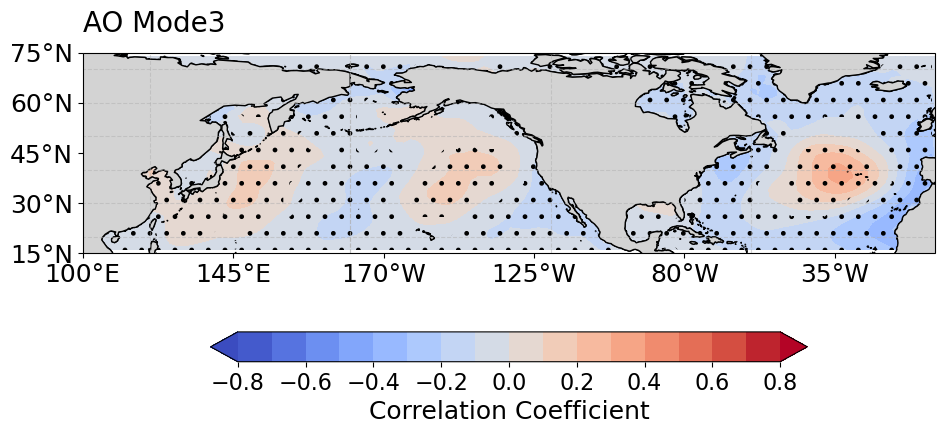

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
import xarray as xr

# 1. 讀取 NetCDF 檔案並選取特定模態
nc_path = str(DATA_ROOT / 'data' / 'raw' / 'PanBasin_PO_AO_LOOCV_patterns_1981_2020.nc')
ds = xr.open_dataset(nc_path)

basin_name = 'AO'
mode_num = 3
mode_title = f'{basin_name} Mode{mode_num}'

po_mode_corr = ds['mean_reg'].sel(basin=basin_name, mode=mode_num)
po_mode_sig  = ds['sig_mask_reg'].sel(basin=basin_name, mode=mode_num)

# 2. 處理經度閉合（避免在中央經線 225° 出現白色裂縫）
lons = po_mode_corr['lon'].values
lats = po_mode_corr['lat'].values

# 將顯著遮罩中非顯著 (0) 的部分轉為 NaN，這樣打點才不會整片填滿
mask_sig_nan = np.where(po_mode_sig.values == 1, 1.0, np.nan)

data_mean_cyc, lon_cyc = add_cyclic_point(po_mode_corr.values, coord=lons)
mask_cyc, _            = add_cyclic_point(mask_sig_nan, coord=lons)

# 3. 建立畫布與投影
fig = plt.figure(figsize=(11, 8.5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=225))

# A. 平均海溫相關係數底圖填色
clevs = np.arange(-0.8, 0.81, 0.1)
cs = ax.contourf(
    lon_cyc,
    lats,
    data_mean_cyc,
    clevs,
    transform=ccrs.PlateCarree(),
    cmap='coolwarm',
    extend='both'
)

# B. 顯著性 p < 0.05 區域打點 (Stippling)
ax.contourf(
    lon_cyc,
    lats,
    mask_cyc,
    [0, 1],
    transform=ccrs.PlateCarree(),
    colors='none',
    hatches=['.', '.'],
    extend='both',
    alpha=0
)

# C. 陸地遮罩與海岸線
ax.coastlines(resolution='50m', color='black', linewidth=1)
ax.add_feature(cfeature.LAND, facecolor='lightgray', edgecolor='black', zorder=2)
ax.gridlines(draw_labels=False, linestyle='--', alpha=0.5)

# D. 鎖定全洋盆經緯度範圍 (100°E ~ 355°E, 15°N ~ 75°N)
ax.set_extent([100, 355, 15, 75], crs=ccrs.PlateCarree())

# E. 座標刻度標示
ax.set_xticks(np.arange(100, 355, 45), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(15, 76, 15), crs=ccrs.PlateCarree())
ax.xaxis.set_major_formatter(cticker.LongitudeFormatter())
ax.yaxis.set_major_formatter(cticker.LatitudeFormatter())
ax.tick_params(axis='both', labelsize=18)

# F. 色彩條 (Colorbar)
cbar = plt.colorbar(
    cs,
    orientation='horizontal',
    shrink=0.7,
    pad=0.12,
    ticks=np.arange(-0.8, 0.81, 0.2)
)
cbar.ax.tick_params(labelsize=16)
cbar.set_label('Correlation Coefficient', fontsize=18)

# G. 標題
plt.title(f'{mode_title}', fontsize=20, loc='left', pad=15)

# 4. 顯示或存檔
# 如果在 Jupyter Notebook / 本地 GUI 環境下想直接彈出視窗看圖：
plt.show()

# 如果在伺服器 / Linux 無 GUI 環境，請改用存檔：
# plt.savefig(f'{mode_title}_PanBasin_from_nc.png', dpi=300, bbox_inches='tight')
# plt.close(fig)